# 03. Строительство: прочность бетона — регрессия и контроль качества

**Дисциплина:** «Управление и аналитика данных на предприятии» · СПбПУ, ИПМЭиТ · Лекция 7

**Профиль:** Менеджмент в девелопменте и строительстве

**Бизнес-вопрос:** Можно ли по рецептуре смеси и возрасту бетона (а) спрогнозировать прочность на сжатие и (б) заранее отсеять замесы, которые не наберут требуемую прочность, — не дожидаясь лабораторных испытаний?

**Данные:** `Concrete_Data.xls` (**Excel**) — 1030 лабораторных испытаний: 7 компонентов смеси (кг/м³), возраст (сут.), прочность (МПа). Источник: [UCI ML Repository, Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength), Yeh, 1998, CC BY 4.0.

---
Ноутбук построен по единому сценарию из 10 шагов (см. лекцию 7): *вопрос → загрузка → паспорт данных → очистка → разведка → связи и тренды → постановка ML-задачи → train/test → модель и базовая линия → качество и вывод для бизнеса*. Запуск: «Среда выполнения → Выполнить всё». Данные загружаются по постоянной ссылке с GitHub — ничего загружать вручную не нужно.

## Шаг 1. Вопрос и гипотеза

* **H1 (закон Абрамса):** чем ниже водоцементное отношение В/Ц, тем выше прочность.
* **H2:** прочность растёт с возрастом нелинейно — быстро в первые недели, затем медленно.
* Две ML-задачи на одних данных: **регрессия** (сколько МПа?) и **классификация** (наберёт ли порог?).

In [1]:
# Шаг 0. Подключаем библиотеки (как в базовом примере)
import numpy as np                 # вычисления
import pandas as pd                # таблицы
import seaborn as sns              # графики
import matplotlib.pyplot as plt    # графики

sns.set_theme(style="whitegrid", palette=["#37B34A", "#244128", "#7248A0", "#F39768", "#DA4927"])
pd.set_option("display.max_columns", 30)

## Шаги 2–3. Загрузка Excel-файла и паспорт данных

`pd.read_excel` читает .xls/.xlsx так же просто, как CSV. Длинные названия столбцов заменим на короткие.

In [2]:
beton = pd.read_excel("https://raw.githubusercontent.com/alejanro85/uad-lecture7-ml/main/data/Concrete_Data.xls")
beton.columns = ["cement", "slag", "fly_ash", "water", "superplast", "coarse_aggr", "fine_aggr", "age_days", "strength_mpa"]
print(beton.shape, "| пропусков:", beton.isna().sum().sum(), "| дублей:", beton.duplicated().sum())
beton.describe().T.round(1)

(1030, 9) | пропусков: 0 | дублей: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.2,104.5,102.0,192.4,272.9,350.0,540.0
slag,1030.0,73.9,86.3,0.0,0.0,22.0,143.0,359.4
fly_ash,1030.0,54.2,64.0,0.0,0.0,0.0,118.3,200.1
water,1030.0,181.6,21.4,121.8,164.9,185.0,192.0,247.0
superplast,1030.0,6.2,6.0,0.0,0.0,6.4,10.2,32.2
coarse_aggr,1030.0,972.9,77.8,801.0,932.0,968.0,1029.4,1145.0
fine_aggr,1030.0,773.6,80.2,594.0,731.0,779.5,824.0,992.6
age_days,1030.0,45.7,63.2,1.0,7.0,28.0,56.0,365.0
strength_mpa,1030.0,35.8,16.7,2.3,23.7,34.4,46.1,82.6


**Вывод:** 1030 испытаний, пропусков нет, но есть **25 полных дублей** (повторные записи) — удалим. Прочность от 2 до 83 МПа, возраст от 1 до 365 суток.

## Шаг 4. Подготовка: дубли и инженерные признаки

Предметное знание превращаем в признаки: **В/Ц** (водоцементное отношение) и **логарифм возраста** (нелинейный набор прочности).

In [3]:
beton = beton.drop_duplicates().reset_index(drop=True)
beton["w_c"] = beton["water"] / beton["cement"]
beton["log_age"] = np.log(beton["age_days"])
beton.shape

(1005, 11)

## Шаги 5–6. Разведка: проверяем гипотезы

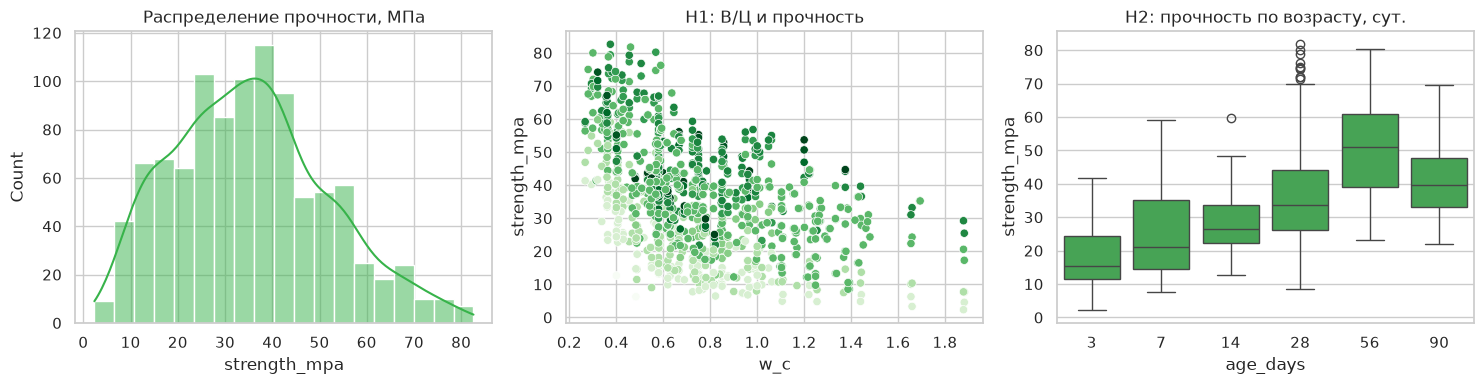

w_c            -0.49
log_age         0.56
cement          0.49
superplast      0.34
strength_mpa    1.00
Name: strength_mpa, dtype: float64

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(beton["strength_mpa"], kde=True, ax=ax[0]); ax[0].set_title("Распределение прочности, МПа")
sns.scatterplot(data=beton, x="w_c", y="strength_mpa", hue="log_age", palette="Greens", ax=ax[1], legend=False); ax[1].set_title("H1: В/Ц и прочность")
sns.boxplot(data=beton[beton.age_days.isin([3, 7, 14, 28, 56, 90])], x="age_days", y="strength_mpa", ax=ax[2]); ax[2].set_title("H2: прочность по возрасту, сут.")
plt.tight_layout(); plt.show()
beton[["w_c", "log_age", "cement", "superplast", "strength_mpa"]].corr()["strength_mpa"].round(2)

**Вывод по шагам 5–6:** обе гипотезы подтверждаются: связь с В/Ц — отрицательная (чем больше воды на единицу цемента, тем слабее бетон); прочность резко растёт до 28 суток, дальше — медленно.

## Шаги 7–10 (А). Регрессия: прогноз прочности в МПа

Метрики регрессии: **MAE** — средняя ошибка в МПа; **R²** — доля объяснённой изменчивости (1 — идеал).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

base_cols = ["cement", "slag", "fly_ash", "water", "superplast", "coarse_aggr", "fine_aggr", "age_days"]
fe_cols = ["cement", "slag", "fly_ash", "water", "superplast", "coarse_aggr", "fine_aggr", "log_age", "w_c"]
y_reg = beton["strength_mpa"]
for name, cols in [("исходные признаки", base_cols), ("+ log(возраст), В/Ц", fe_cols)]:
    X_tr, X_te, y_tr, y_te = train_test_split(beton[cols], y_reg, test_size=0.25, random_state=42)
    reg = LinearRegression().fit(X_tr, y_tr)
    p = reg.predict(X_te)
    print(f"{name:<22} MAE = {mean_absolute_error(y_te, p):.1f} МПа   R² = {r2_score(y_te, p):.2f}")

исходные признаки      MAE = 8.9 МПа   R² = 0.56
+ log(возраст), В/Ц    MAE = 5.8 МПа   R² = 0.80


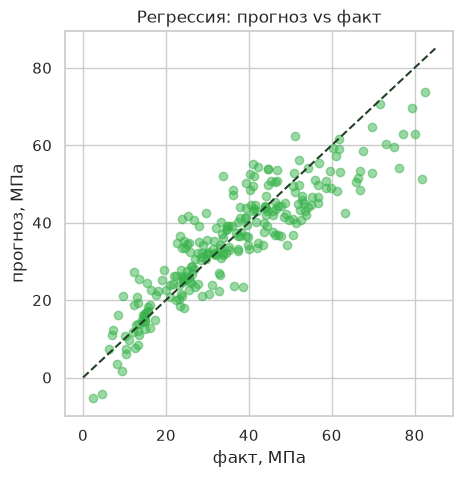

In [6]:
plt.figure(figsize=(5, 5))
plt.scatter(y_te, p, alpha=0.5, color="#37B34A"); plt.plot([0, 85], [0, 85], "--", color="#244128")
plt.xlabel("факт, МПа"); plt.ylabel("прогноз, МПа"); plt.title("Регрессия: прогноз vs факт"); plt.show()

**Вывод (А):** два «инженерных» признака заметно повышают качество той же линейной модели (см. рост R² и снижение MAE). Предметное знание важнее сложности алгоритма.

## Шаги 7–10 (Б). Классификация: «замес наберёт ≥ 30 МПа»

Порог 30 МПа — условный учебный критерий приёмки (порядка класса B25 по требуемой средней прочности). Важная ошибка — **FP: принять слабый бетон** → следим за **precision** класса «годен».

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

def quality(y_true, y_pred, y_proba=None, name="модель"):
    """Печатает ключевые метрики качества классификатора одной строкой."""
    line = (f"{name:<28} accuracy={accuracy_score(y_true, y_pred):.3f}  "
            f"precision={precision_score(y_true, y_pred, zero_division=0):.3f}  "
            f"recall={recall_score(y_true, y_pred):.3f}  f1={f1_score(y_true, y_pred):.3f}")
    if y_proba is not None:
        line += f"  ROC-AUC={roc_auc_score(y_true, y_proba):.3f}"
    print(line)

THRESHOLD_MPA = 30
y = (beton["strength_mpa"] >= THRESHOLD_MPA).astype(int)
print("Доля годных:", round(y.mean(), 3))
X_tr, X_te, y_tr, y_te = train_test_split(beton[fe_cols], y, test_size=0.25, random_state=42, stratify=y)
quality(y_te, DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr).predict(X_te), name="Базовая линия")
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
pred, proba = clf.predict(X_te), clf.predict_proba(X_te)[:, 1]
quality(y_te, pred, proba, name="Логистическая регрессия")
strict = (proba >= 0.8).astype(int)
quality(y_te, strict, proba, name="Строгий порог p ≥ 0,8")

Доля годных: 0.605
Базовая линия                accuracy=0.603  precision=0.603  recall=1.000  f1=0.752
Логистическая регрессия      accuracy=0.909  precision=0.911  recall=0.941  f1=0.926  ROC-AUC=0.957
Строгий порог p ≥ 0,8        accuracy=0.857  precision=0.953  recall=0.803  f1=0.871  ROC-AUC=0.957


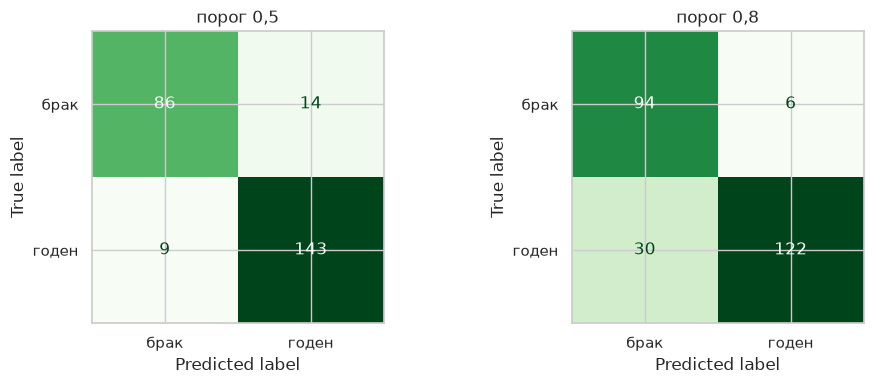

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["брак", "годен"]).plot(ax=ax[0], cmap="Greens", colorbar=False); ax[0].set_title("порог 0,5")
ConfusionMatrixDisplay(confusion_matrix(y_te, strict), display_labels=["брак", "годен"]).plot(ax=ax[1], cmap="Greens", colorbar=False); ax[1].set_title("порог 0,8")
plt.tight_layout(); plt.show()

## Итоговые выводы для бизнеса

1. **Регрессия:** прочность прогнозируется по рецептуре со средней ошибкой ≈ 6 МПа (R² = 0,80 против 0,56 на «сырых» признаках) после добавления двух инженерных признаков.
2. **Контроль качества:** классификатор отделяет «годные» замесы значительно лучше базовой линии; **строгий порог 0,8** повышает precision — меньше риска принять слабый бетон, но больше замесов уходит на лабораторную проверку.
3. **Управленческий эффект:** лаборатория проверяет в первую очередь «сомнительные» замесы, а не все подряд; рецептуры с высоким В/Ц — кандидаты на пересмотр.
4. **Ограничения:** лабораторные данные из одного источника (Тайвань, 1990-е); для стройплощадки нужны данные своего поставщика бетона.